# 03 - Entrenamiento y evaluación del modelo

Este notebook es **otro plano de consumo**: no toca el CSV ni repite el ETL.
Solo se conecta a `database/prestamos.db` y consume la capa curada con SQL.

Pregunta del modelo: **¿la solicitud de préstamo debería ser aprobada o rechazada?**

In [1]:
import os
import sqlite3

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, confusion_matrix,
                             f1_score, make_scorer, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

sns.set_theme(style="whitegrid")
RUTA_BD = "../database/prestamos.db"
RUTA_MODELO = "../models/modelo_final.joblib"
RUTA_FIGURAS = "../reports/figuras/"
SEMILLA = 42
os.makedirs(RUTA_FIGURAS, exist_ok=True)
os.makedirs("../models", exist_ok=True)

## 1. Consulta de datos desde la base de datos

In [2]:
conexion = sqlite3.connect(RUTA_BD)

# las columnas predictoras se leen del diccionario que dejó el ETL
predictoras = pd.read_sql(
    "SELECT columna FROM metadatos_columnas WHERE rol = 'predictora'", conexion
)["columna"].tolist()
objetivo = pd.read_sql("SELECT columna FROM metadatos_columnas WHERE rol = 'objetivo'", conexion)["columna"][0]
print(len(predictoras), "predictoras | objetivo:", objetivo)

16 predictoras | objetivo: aprobado


In [3]:
consulta_train = f"SELECT {', '.join(predictoras)}, {objetivo} FROM vw_entrenamiento"
consulta_test = f"SELECT {', '.join(predictoras)}, {objetivo} FROM vw_prueba"
print(consulta_train)

entrenamiento = pd.read_sql(consulta_train, conexion)
prueba = pd.read_sql(consulta_test, conexion)
conexion.close()

print("train:", entrenamiento.shape, "| test:", prueba.shape)

SELECT es_hombre, casado, dependientes, graduado, independiente, zona_semiurbana, zona_urbana, historial_bueno, historial_desconocido, plazo_meses, log_ingreso_solicitante, log_ingreso_coaplicante, log_ingreso_total, log_monto_prestamo, cuota_aprox, relacion_cuota_ingreso, aprobado FROM vw_entrenamiento
train: (491, 17) | test: (123, 17)


## 2. Preparación de variables y separación train/test
El split ya viene hecho desde el ETL (columna `conjunto`, estratificado con semilla 42),
así los valores de imputación también se calcularon solo con train.

In [4]:
X_train, y_train = entrenamiento[predictoras], entrenamiento[objetivo]
X_test, y_test = prueba[predictoras], prueba[objetivo]

assert objetivo not in X_train.columns  # la variable objetivo no entra como predictora
print("% aprobados train:", round(y_train.mean() * 100, 1), "| test:", round(y_test.mean() * 100, 1))

% aprobados train: 68.6 | test: 69.1


## 3. Modelos a comparar

Se prueban 6 modelos. Los que dependen de distancias o coeficientes (logística, KNN) llevan
`StandardScaler` **dentro** del pipeline, para que el escalado se ajuste solo con los datos de entrenamiento.

Para el desbalance (69/31) se usa `class_weight="balanced"` en los modelos que lo permiten.
Se deja también una logística **sin** balancear para ver el efecto.

In [5]:
modelos = {
    "Regresión logística balanceada": make_pipeline(
        StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Logística sin balancear": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=1000)),
    "Árbol de decisión": DecisionTreeClassifier(
        max_depth=4, class_weight="balanced", random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=6, min_samples_leaf=5, class_weight="balanced", random_state=SEMILLA),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, max_depth=2, learning_rate=0.05, random_state=SEMILLA),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}

## 4. Validación cruzada (5 folds estratificados, solo con train)

Además de las métricas clásicas se mide la **especificidad** (recall de la clase "rechazado"):
de los préstamos que debían rechazarse, ¿cuántos detecta el modelo?

In [6]:
metricas_cv = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "especificidad": make_scorer(recall_score, pos_label=0),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

filas = []
for nombre, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas_cv)
    fila = {"modelo": nombre}
    for m in metricas_cv:
        fila[m] = r["test_" + m].mean()
    fila["auc_desv"] = r["test_roc_auc"].std()
    filas.append(fila)

resultados_cv = pd.DataFrame(filas).set_index("modelo").round(3)
resultados_cv

C:\Users\juanc\Downloads\proyecto-suficiencia-admin-datos\proyecto-suficiencia-admin-datos\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\juanc\Downloads\proyecto-suficiencia-admin-datos\proyecto-suficiencia-admin-datos\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\juanc\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 555, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "

,accuracy,precision,recall,f1,roc_auc,especificidad,auc_desv
modelo,,,,,,,
Regresión logística balanceada,0.745,0.797,0.846,0.820,0.740,0.525,0.036
Logística sin balancear,0.794,0.784,0.970,0.866,0.740,0.408,0.037
Árbol de decisión,0.756,0.784,0.893,0.834,0.674,0.454,0.079
Random Forest,0.729,0.785,0.837,0.809,0.753,0.493,0.040
Gradient Boosting,0.784,0.784,0.949,0.858,0.763,0.422,0.038
KNN,0.758,0.751,0.970,0.846,0.699,0.292,0.040


## 5. Criterio de negocio: costo de los errores

En este problema la clase positiva es **aprobado (1)**:
- **Falso positivo (FP):** el modelo aprueba a alguien que debía rechazarse → el banco puede **perder el capital** prestado.
- **Falso negativo (FN):** el modelo rechaza a alguien que sí calificaba → el banco **deja de ganar** intereses y molesta a un buen cliente.

Un FP es más caro que un FN. Como supuesto de trabajo se asume que **un FP cuesta 3 veces un FN**
(el costo real lo tendría que definir el área de riesgo). Con eso se calcula un costo usando
predicciones de validación cruzada (sin tocar el test).

In [7]:
COSTO_FP, COSTO_FN = 3, 1

for nombre, modelo in modelos.items():
    pred_cv = cross_val_predict(modelo, X_train, y_train, cv=cv)
    tn, fp, fn, tp = confusion_matrix(y_train, pred_cv).ravel()
    resultados_cv.loc[nombre, "FP"] = fp
    resultados_cv.loc[nombre, "FN"] = fn
    resultados_cv.loc[nombre, "costo"] = COSTO_FP * fp + COSTO_FN * fn

resultados_cv.sort_values("costo")

,accuracy,precision,recall,f1,roc_auc,especificidad,auc_desv,FP,FN,costo
modelo,,,,,,,,,,
Regresión logística balanceada,0.745,0.797,0.846,0.820,0.740,0.525,0.036,73.0,52.0,271.0
Logística sin balancear,0.794,0.784,0.970,0.866,0.740,0.408,0.037,91.0,10.0,283.0
Gradient Boosting,0.784,0.784,0.949,0.858,0.763,0.422,0.038,89.0,17.0,284.0
Árbol de decisión,0.756,0.784,0.893,0.834,0.674,0.454,0.079,84.0,36.0,288.0
Random Forest,0.729,0.785,0.837,0.809,0.753,0.493,0.040,78.0,55.0,289.0
KNN,0.758,0.751,0.970,0.846,0.699,0.292,0.040,109.0,10.0,337.0


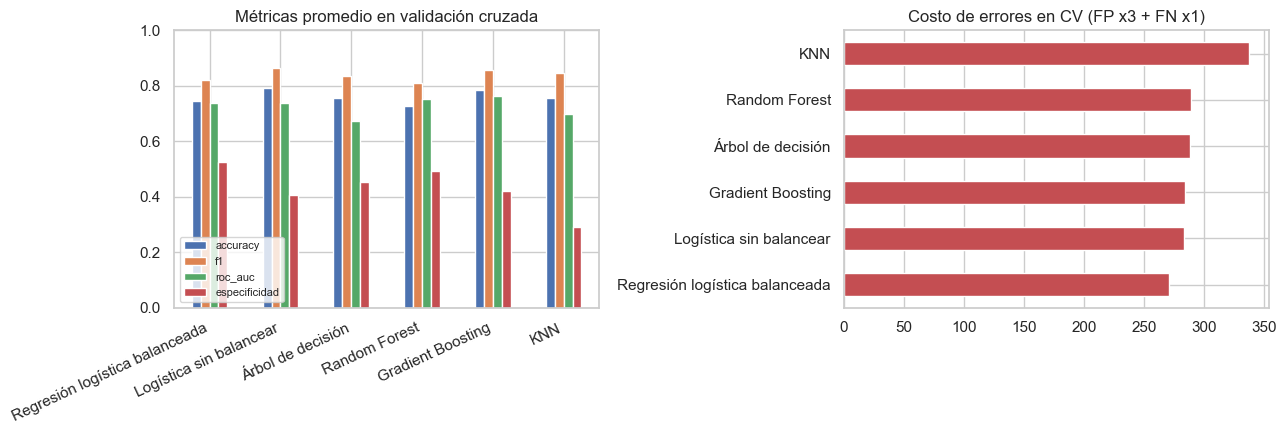

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
resultados_cv[["accuracy", "f1", "roc_auc", "especificidad"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Métricas promedio en validación cruzada")
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=25, ha="right")
axes[0].legend(loc="lower left", fontsize=8)
resultados_cv["costo"].sort_values().plot(kind="barh", ax=axes[1], color="#C44E52")
axes[1].set_ylabel("")
axes[1].set_title(f"Costo de errores en CV (FP x{COSTO_FP} + FN x{COSTO_FN})")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "comparacion_modelos.png", dpi=120)
plt.show()

**Lectura:**
- Por accuracy ganan la logística sin balancear y Gradient Boosting (~0.79), pero es porque aprueban a casi todos:
  su especificidad es ~0.41, o sea que **dejan pasar a la mayoría de los que debían rechazarse**.
- KNN es el peor: aprueba casi todo.
- La **regresión logística balanceada** tiene el menor costo (271) y la mayor especificidad (0.525):
  es la que más rechazos detecta. A cambio sacrifica algo de accuracy.
- Les siguen la logística sin balancear (283) y Gradient Boosting (284): casi no rechazan a buenos clientes,
  pero aprueban a muchos que debían rechazarse.
- Random Forest balanceado (289) no mejora a la logística ni en costo ni en detección de rechazos, y es menos interpretable.

## 6. Entrenamiento final y evaluación en el set de prueba

In [9]:
filas_test = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas_test.append({
        "modelo": nombre,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, prob),
        "especificidad": recall_score(y_test, pred, pos_label=0),
        "FP": fp, "FN": fn, "costo": COSTO_FP * fp + COSTO_FN * fn,
    })
resultados_test = pd.DataFrame(filas_test).set_index("modelo").round(3)
resultados_test

,accuracy,precision,recall,f1,roc_auc,especificidad,FP,FN,costo
modelo,,,,,,,,,
Regresión logística balanceada,0.789,0.847,0.847,0.847,0.862,0.658,13,13,52
Logística sin balancear,0.862,0.840,0.988,0.908,0.858,0.579,16,1,49
Árbol de decisión,0.821,0.846,0.906,0.875,0.831,0.632,14,8,50
Random Forest,0.821,0.880,0.859,0.869,0.818,0.737,10,12,42
Gradient Boosting,0.854,0.845,0.965,0.901,0.835,0.605,15,3,48
KNN,0.780,0.769,0.976,0.860,0.789,0.342,25,2,77


En el test (123 filas) el orden cambia respecto a la CV: Random Forest tiene el menor costo (42) y la logística
balanceada queda en 52. Pero cinco de los seis modelos quedan entre 42 y 52, y esa diferencia equivale a unas
3 solicitudes mal aprobadas (Random Forest: 10 FP, logística: 13 FP). Con un test tan pequeño eso es ruido, por eso la decisión se toma con la validación cruzada
(491 filas, 5 particiones), que es más estable. Elegir el modelo mirando el test sería hacer trampa con los datos de prueba.

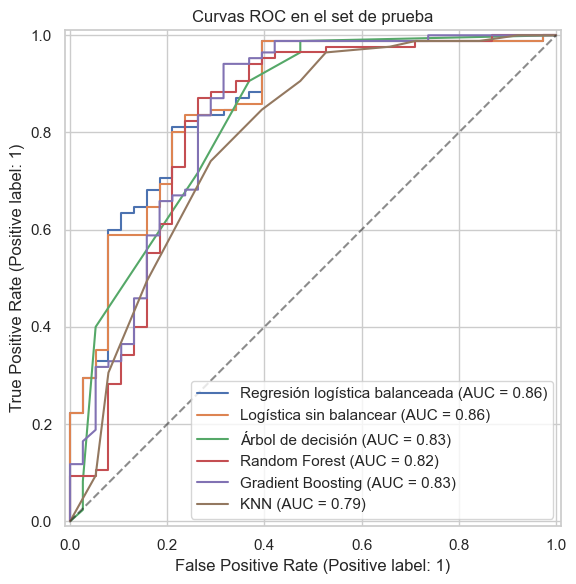

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
for nombre, modelo in modelos.items():
    RocCurveDisplay.from_estimator(modelo, X_test, y_test, name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_title("Curvas ROC en el set de prueba")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "curvas_roc.png", dpi=120)
plt.show()

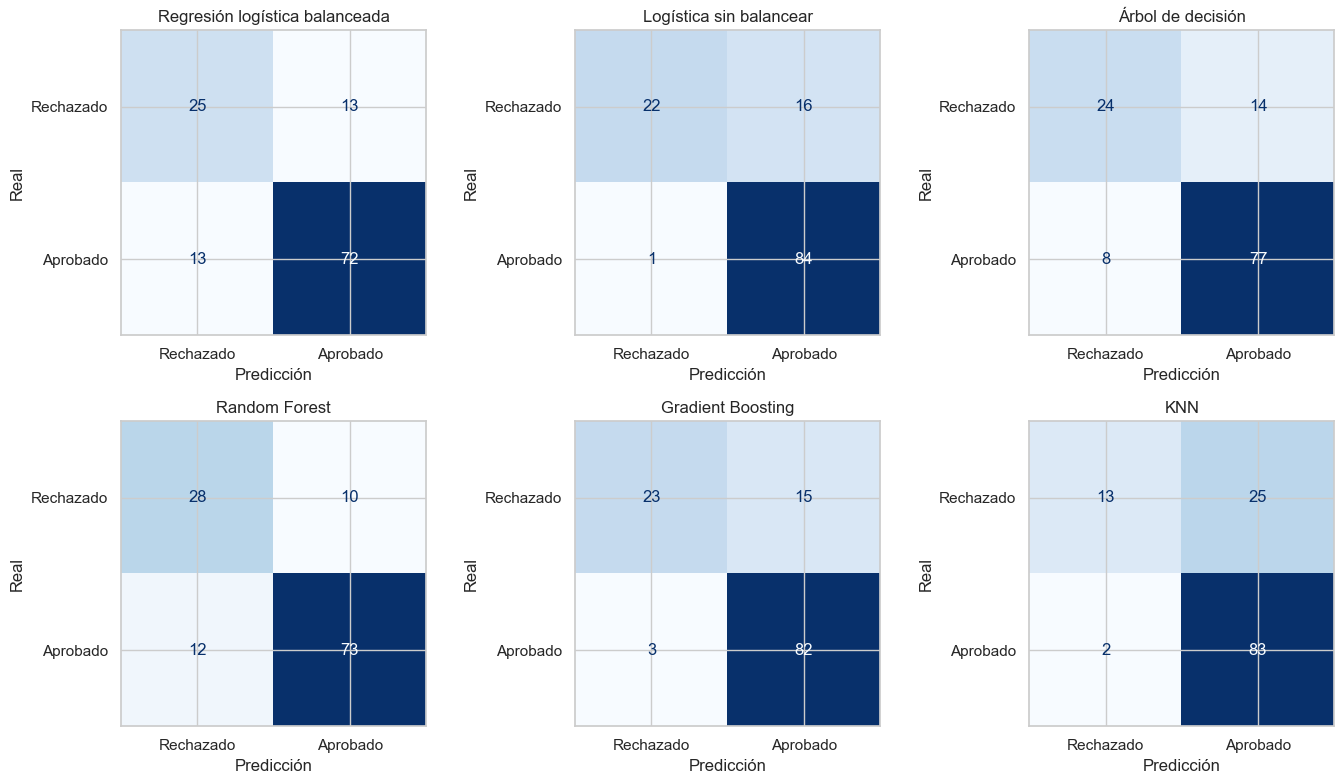

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (nombre, modelo) in zip(axes.flat, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(
        modelo, X_test, y_test, display_labels=["Rechazado", "Aprobado"], ax=ax, colorbar=False, cmap="Blues")
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Real")
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

## 7. Selección del modelo final

Se elige el modelo con **menor costo de errores en validación cruzada** (no en test, para no
elegir "mirando" el set de prueba).

In [12]:
nombre_final = resultados_cv["costo"].idxmin()
modelo_final = modelos[nombre_final]
print("Modelo seleccionado:", nombre_final)
resultados_test.loc[[nombre_final]]

Modelo seleccionado: Regresión logística balanceada


,accuracy,precision,recall,f1,roc_auc,especificidad,FP,FN,costo
modelo,,,,,,,,,
Regresión logística balanceada,0.789,0.847,0.847,0.847,0.862,0.658,13,13,52


**Justificación:**
1. **Menor costo de negocio** en validación cruzada: es el que mejor equilibra no aprobar préstamos riesgosos
   sin rechazar de más a buenos clientes.
2. **ROC-AUC competitivo** con los modelos más complejos (las diferencias de AUC entre modelos están
   dentro de la variación entre folds).
3. **Interpretable:** cada coeficiente dice cuánto sube o baja la probabilidad de aprobación.
   En crédito esto importa porque hay que poder explicarle al cliente y al regulador por qué se rechazó.
4. Con un dataset tan pequeño (491 filas de train), un modelo simple generaliza mejor que uno complejo.

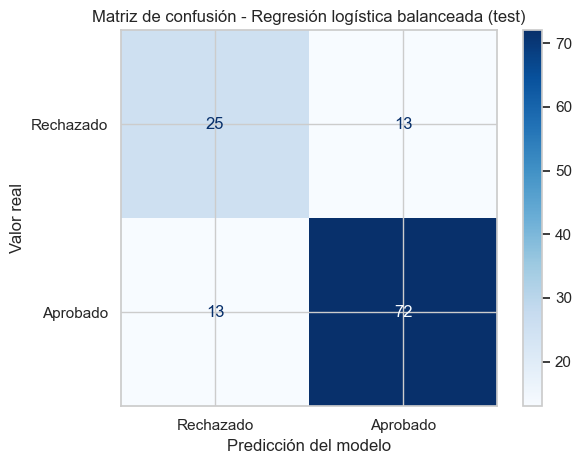

In [13]:
ConfusionMatrixDisplay.from_estimator(
    modelo_final, X_test, y_test, display_labels=["Rechazado", "Aprobado"], cmap="Blues")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.title(f"Matriz de confusión - {nombre_final} (test)")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "matriz_confusion_final.png", dpi=120)
plt.show()

## 8. Análisis de falsos positivos y falsos negativos

In [14]:
pred_final = modelo_final.predict(X_test)
tn, fp, fn, tp = confusion_matrix(y_test, pred_final).ravel()
print(f"Verdaderos rechazos (TN): {tn}")
print(f"Falsos positivos (FP, aprobó a quien debía rechazarse): {fp}")
print(f"Falsos negativos (FN, rechazó a quien calificaba): {fn}")
print(f"Verdaderas aprobaciones (TP): {tp}")

Verdaderos rechazos (TN): 25
Falsos positivos (FP, aprobó a quien debía rechazarse): 13
Falsos negativos (FN, rechazó a quien calificaba): 13
Verdaderas aprobaciones (TP): 72


In [15]:
# ¿cómo son los falsos positivos?
analisis = prueba.copy()
analisis["prediccion"] = pred_final
analisis["prob_aprobacion"] = modelo_final.predict_proba(X_test)[:, 1]
falsos_positivos = analisis[(analisis.aprobado == 0) & (analisis.prediccion == 1)]
print("Historial bueno en los FP:", falsos_positivos["historial_bueno"].mean().round(2))
falsos_positivos[["historial_bueno", "historial_desconocido", "log_ingreso_total",
                  "log_monto_prestamo", "prob_aprobacion"]].describe().round(2)

Historial bueno en los FP: 1.0


,historial_bueno,historial_desconocido,log_ingreso_total,log_monto_prestamo,prob_aprobacion
count,13.0,13.0,13.00,13.00,13.00
mean,1.0,0.0,8.70,5.17,0.60
std,0.0,0.0,0.69,0.45,0.09
min,1.0,0.0,7.73,4.71,0.50
25%,1.0,0.0,8.14,4.91,0.52
50%,1.0,0.0,8.62,5.08,0.60
75%,1.0,0.0,9.39,5.14,0.63
max,1.0,0.0,9.82,6.22,0.78


**Todos** los falsos positivos tienen **buen historial crediticio**: el banco los rechazó por razones
que no están en el dataset (deudas actuales, estabilidad laboral, garantías, etc.).
Es la principal limitación del modelo.

### Efecto del umbral de decisión
Por defecto se aprueba si la probabilidad ≥ 0.5. Subir el umbral reduce FP a cambio de más FN.
Esta tabla le sirve al área de riesgo para decidir el punto de operación.

In [16]:
prob_final = modelo_final.predict_proba(X_test)[:, 1]
tabla_umbral = []
for umbral in [0.4, 0.5, 0.6, 0.7]:
    p = (prob_final >= umbral).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, p).ravel()
    tabla_umbral.append({"umbral": umbral, "FP": fp_, "FN": fn_,
                         "precision": precision_score(y_test, p), "recall": recall_score(y_test, p),
                         "costo": COSTO_FP * fp_ + COSTO_FN * fn_})
pd.DataFrame(tabla_umbral).round(3)

,umbral,FP,FN,precision,recall,costo
0,0.4,15,2,0.847,0.976,47
1,0.5,13,13,0.847,0.847,52
2,0.6,7,27,0.892,0.682,48
3,0.7,3,53,0.914,0.376,62


Se mantiene el umbral en 0.5 para el modelo entregado. Elegir el umbral con el test sería leakage;
lo correcto sería calibrarlo con validación cruzada cuando riesgo defina el costo real.

## 9. Importancia de variables

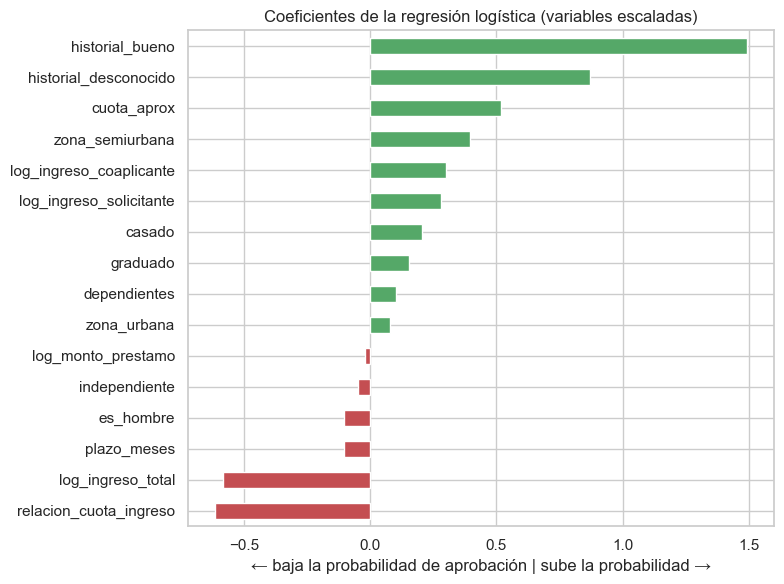

In [17]:
coeficientes = pd.Series(
    modelo_final[-1].coef_[0], index=predictoras
).sort_values()

plt.figure(figsize=(8, 6))
colores = ["#C44E52" if c < 0 else "#55A868" for c in coeficientes]
coeficientes.plot(kind="barh", color=colores)
plt.title("Coeficientes de la regresión logística (variables escaladas)")
plt.xlabel("← baja la probabilidad de aprobación | sube la probabilidad →")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "importancia_variables.png", dpi=120)
plt.show()

In [18]:
# comparación con la importancia del Random Forest
importancia_rf = pd.Series(
    modelos["Random Forest"].feature_importances_, index=predictoras
).sort_values(ascending=False).round(3)
importancia_rf.head(8)

historial_bueno            0.287
relacion_cuota_ingreso     0.115
log_ingreso_total          0.105
log_ingreso_solicitante    0.091
cuota_aprox                0.088
log_monto_prestamo         0.081
log_ingreso_coaplicante    0.061
historial_desconocido      0.048
dtype: float64

Los dos modelos coinciden: **el historial crediticio es por mucho la variable más importante**.
- En la logística, `historial_bueno` (+1.49) e `historial_desconocido` (+0.87) son los coeficientes más grandes.
  Que el "desconocido" sea positivo confirma lo del EDA: esos clientes se parecen más a los de buen historial que a los de mal historial.
- En el Random Forest, `historial_bueno` pesa 0.29 y le sigue `relacion_cuota_ingreso` (0.12).
- Después vienen las variables de capacidad de pago (ingresos, cuota, relación cuota/ingreso) y la zona semiurbana (+0.40).

Ojo: las variables de dinero están relacionadas entre sí (ingreso total, ingresos individuales, cuota, monto).
Por esa multicolinealidad algunos coeficientes salen con signos que parecen raros (por ejemplo `log_ingreso_total`
negativo y `cuota_aprox` positivo). Esas variables hay que leerlas **en conjunto**, no una por una.

## 10. Guardado del modelo entrenado
Se guarda el pipeline completo (escalador + modelo) junto con la lista de columnas,
para que se pueda reutilizar sin repetir el preprocesamiento.

In [19]:
paquete = {
    "modelo": modelo_final,
    "nombre": nombre_final,
    "predictoras": predictoras,
    "umbral": 0.5,
    "metricas_cv": resultados_cv.loc[nombre_final].to_dict(),
    "metricas_test": resultados_test.loc[nombre_final].to_dict(),
}
joblib.dump(paquete, RUTA_MODELO)

# prueba de que se puede volver a cargar y usar
cargado = joblib.load(RUTA_MODELO)
print("Modelo cargado:", cargado["nombre"])
print("Predicciones de ejemplo:", cargado["modelo"].predict(X_test.head(5)))

Modelo cargado: Regresión logística balanceada
Predicciones de ejemplo: [1 0 1 1 0]


## 11. Limitaciones
- Dataset pequeño (614 solicitudes): las métricas varían bastante entre folds.
- El modelo depende mucho de `Credit_History`; sin ese dato pierde gran parte de su poder.
- Las variables de ingreso y monto están correlacionadas, así que sus coeficientes individuales no se deben interpretar por separado.
- No hay variables de deuda actual, empleo o garantías, por eso los falsos positivos tienen buen historial.
- El costo 3:1 es un supuesto; con costos reales del banco la elección del modelo o del umbral podría cambiar.
- El modelo aprende las decisiones históricas del banco: si esas decisiones tenían sesgos, el modelo los repite.
  Por eso conviene revisar periódicamente variables sensibles como `es_hombre`.